# PRAKTIKUM
## Nama : Oktova Yoga Praditia Samosir
## NIM  : 42324001
## Prodi: D3 Teknologi Informasi 

=== Distance Matrix (Euclidean) ===
          a         b         c         d         e         f
a  0.000000  0.707107  5.656854  3.605551  4.242641  3.201562
b  0.707107  0.000000  4.949747  2.915476  3.535534  2.500000
c  5.656854  4.949747  0.000000  2.236068  1.414214  2.500000
d  3.605551  2.915476  2.236068  0.000000  1.000000  0.500000
e  4.242641  3.535534  1.414214  1.000000  0.000000  1.118034
f  3.201562  2.500000  2.500000  0.500000  1.118034  0.000000


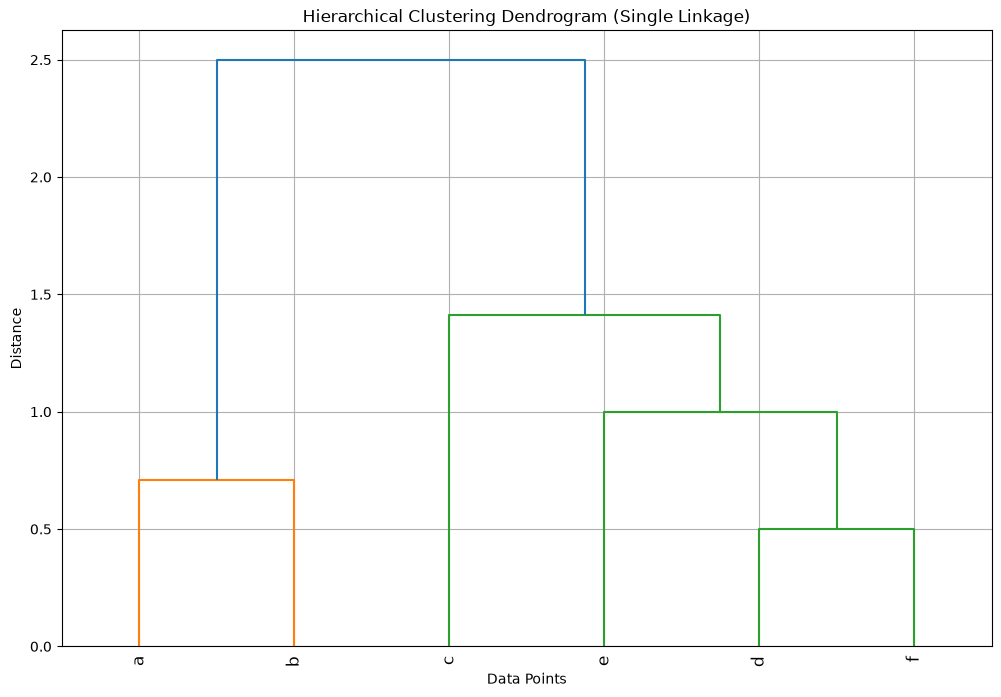

In [9]:
# in 1
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt

# 1. Dataset sederhana
data = np.array([
    [1.0, 1.0],  # a
    [1.5, 1.5],  # b
    [5.0, 5.0],  # c
    [3.0, 4.0],  # d
    [4.0, 4.0],   # e
    [3.0, 3.5]   # f
])

# 2. hitung Distance Matrix (Euclidean Distance)
distance_matrix = pdist(data, metric='euclidean')
distance_df = pd.DataFrame(squareform(distance_matrix),
columns=['a', 'b', 'c', 'd', 'e', 'f'],
index=['a', 'b', 'c', 'd', 'e', 'f'])

# 3. hampilkan Distance Matrix
print("=== Distance Matrix (Euclidean) ===")
print(distance_df)

# 4. hierarchical Clustering (Single Linkage)
linked = linkage(data, method='single')

# 5. plot Dendrogram
plt.figure(figsize=(12, 8))
plt.title("Hierarchical Clustering Dendrogram (Single Linkage)")
dendrogram(linked, labels=['a', 'b', 'c', 'd', 'e', 'f'], leaf_rotation=90)
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.grid(True)
plt.show()

code ini dipakai untuk membuat dendrogram dari dataset sederhana. np.array untuk membuat data 6 titik (a sampai f) dengan 2 fitur. pdist untuk menghitung jarak euclidean antar titik, lalu squareform dan pd.dataframe untuk mengubahnya jadi tabel distance matrix. print untuk menampilkan tabel 6 baris dan 6 kolom itu.

linkage(data, method='single') untuk menggabungkan titik-titik secara bertahap dengan single linkage, yaitu memakai jarak terdekat antar klaster. dendrogram untuk menggambar hasilnya, dan plt.show untuk menampilkannya. di grafik, d dan f paling dulu bergabung (jarak 0.5), lalu a dan b (0.707), kemudian e, c, dan terakhir kelompok a-b digabung di jarak 2.5.

In [ ]:
# in 2
import pandas as pd
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


code ini dipakai untuk membaca data mall customers. pd.read_csv untuk membaca file csv ke dalam tabel df, lalu df.head untuk menampilkan 5 baris pertama dan 5 kolomnya.

In [3]:
# in 3
x = df.iloc[:, [3, 4]].values

code ini dipakai untuk mengambil dua fitur saja. df.iloc[:, [3, 4]] untuk mengambil kolom index 3 dan 4, yaitu annual income dan spending score, lalu values untuk mengubahnya jadi array dan disimpan di x. sel ini tidak menampilkan output apa pun.

In [4]:
# in 4
from sklearn.preprocessing import StandardScaler
data_scaler = StandardScaler()
scaled_data = data_scaler.fit_transform(x)
scaled_data.shape

(200, 2)

code ini dipakai untuk menyamakan skala data. from sklearn.preprocessing import ... untuk mengambil standardscaler, lalu fit_transform untuk mengubah x supaya rata-ratanya 0 dan sebarannya seragam, disimpan di scaled_data. scaled_data.shape untuk menampilkan bentuk datanya, yaitu 200 baris dan 2 kolom.

In [5]:
# in 5
from scipy.cluster.hierarchy import linkage, dendrogram

clustering = linkage(scaled_data, method="complete", metric="euclidean")

code ini dipakai untuk membuat hierarchical clustering pada data mall customers. linkage(scaled_data, ...) untuk menggabungkan data secara bertahap, yang dimana method="complete" artinya memakai jarak terjauh antar klaster dan metric="euclidean" artinya jaraknya dihitung dengan jarak euclidean. hasilnya disimpan di clustering. sel ini tidak menampilkan output apa pun.

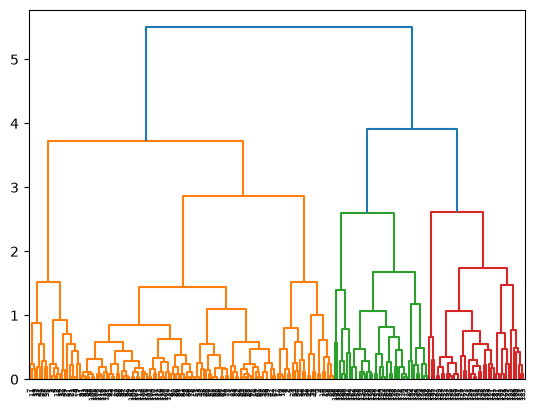

In [6]:
# in 6
import matplotlib.pyplot as plt

dendrogram(clustering)
plt.show()

code ini dipakai untuk membuat hierarchical clustering pada data mall customers. linkage(scaled_data, ...) untuk menggabungkan data secara bertahap, yang dimana method="complete" artinya memakai jarak terjauh antar klaster dan metric="euclidean" artinya jaraknya dihitung dengan jarak euclidean. hasilnya disimpan di clustering. sel ini tidak menampilkan output apa pun.

Linkage matrix (single)
[[3.    5.    0.5   2.   ]
 [0.    1.    0.707 2.   ]
 [4.    6.    1.    3.   ]
 [2.    8.    1.414 4.   ]
 [7.    9.    2.5   6.   ]]
Linkage matrix (complete)
[[3.    5.    0.5   2.   ]
 [0.    1.    0.707 2.   ]
 [4.    6.    1.118 3.   ]
 [2.    8.    2.5   4.   ]
 [7.    9.    5.657 6.   ]]
Linkage matrix (average)
[[3.    5.    0.5   2.   ]
 [0.    1.    0.707 2.   ]
 [4.    6.    1.059 3.   ]
 [2.    8.    2.05  4.   ]
 [7.    9.    3.826 6.   ]]


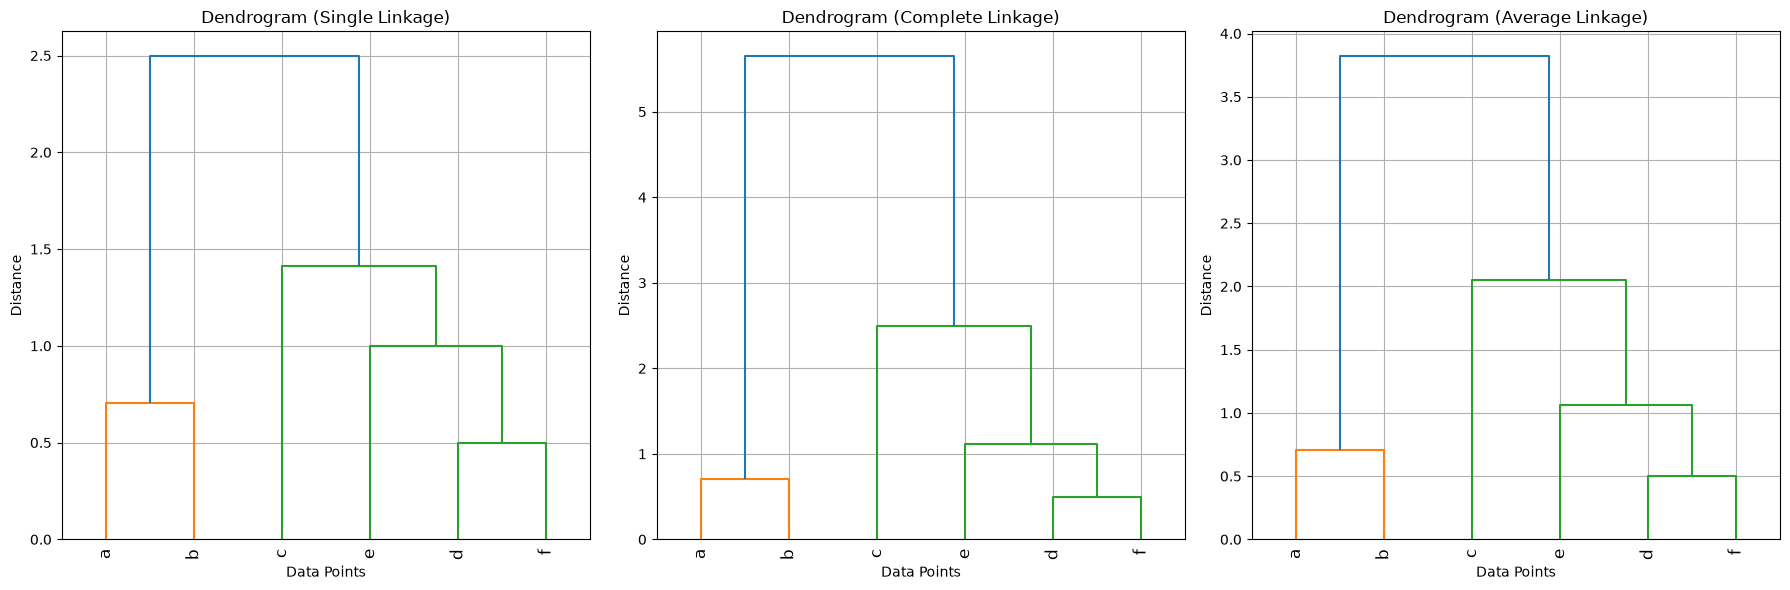

In [8]:
# Tugas 

label = ['a', 'b', 'c', 'd', 'e', 'f']
metode = ['single', 'complete', 'average']

plt.figure(figsize=(18, 6))
for i, m in enumerate(metode, start=1):
    linked_m = linkage(data, method=m)

    plt.subplot(1, 3, i)
    plt.title(f"Dendrogram ({m.capitalize()} Linkage)")
    dendrogram(linked_m, labels=label, leaf_rotation=90)
    plt.xlabel("Data Points")
    plt.ylabel("Distance")
    plt.grid(True)

    print(f"Linkage matrix ({m})")
    print(np.round(linked_m, 3))

plt.tight_layout()
plt.show()

code ini dipakai untuk membandingkan dendrogram single, complete, dan average linkage pada dataset sederhana. metode untuk menyimpan tiga jenis linkage yang mau dibandingkan. for i, m in enumerate(...) untuk mengulang tiap metode, yang dimana di tiap putaran linkage(data, method=m) membuat penggabungannya, plt.subplot(1, 3, i) menyiapkan tempat grafik berdampingan, dan dendrogram menggambarnya. print untuk menampilkan linkage matrix tiap metode.

single linkage menghasilkan tinggi paling rendah karena memakai jarak terdekat, complete linkage paling tinggi karena memakai jarak terjauh, dan average linkage ada di tengah-tengahnya. d + f dan a + b tingginya sama di ketiganya karena masing-masing hanya berisi dua titik, jadi jarak terdekat, terjauh, dan rata-ratanya sama.